# Analisis Risiko Gangguan Rantai Pasok Global 2026

## 1. Latar Belakang
Keterlambatan dan gangguan pengiriman meningkatkan biaya, merusak kepercayaan pelanggan, dan mengganggu stok. Tim logistik perlu tahu **kondisi apa yang paling sering berujung gangguan** supaya mitigasi bisa difokuskan, bukan disebar rata ke semua pengiriman.

## 2. Objective (kerangka SMART)

**Objective utama:** Mengidentifikasi faktor-faktor yang paling berkaitan dengan gangguan pengiriman dan lead time pada data supply chain global 2026, lalu menghasilkan rekomendasi mitigasi yang menyasar segmen paling berisiko.

| Aspek | Penjabaran |
|---|---|
| **S**pecific | Menganalisis hubungan *Weather_Condition, Transport_Mode, Geopolitical_Risk_Score, Carrier_Reliability_Score, Distance_km* terhadap *Disruption_Occurred* dan *Lead_Time_Days*, baik satu per satu (univariat) maupun beberapa faktor sekaligus (multivariat, termasuk interaksi antar faktor). |
| **M**easurable | (a) Baseline: % pengiriman terganggu dan lead time rata-rata/median. (b) Ranking minimal 5 faktor berdasarkan selisih % gangguan antar kategori (spread), disertai uji signifikansi statistik (α = 0,05). (c) Minimal 3 rekomendasi mitigasi, masing-masing menyebut segmen target dan angka pendukungnya, termasuk strategi untuk tiap kondisi cuaca. (d) Estimasi dampak finansial (USD) dari gangguan dan potensi penghematan dari mitigasi. |
| **A**chievable | Data sudah tersedia dalam satu file CSV; cukup dengan analisis deskriptif (groupby, korelasi, tren), uji statistik, dan regresi menggunakan pandas, seaborn, dan scipy. |
| **R**elevant | Hasilnya dipakai tim logistik/procurement untuk memilih carrier, moda, dan jadwal pengiriman yang menurunkan risiko gangguan. |
| **T**ime-bound | Analisis dan rekomendasi selesai dalam 1 minggu kerja (silakan sesuaikan dengan tenggat sebenarnya). |

> **Catatan batasan:** analisis ini bersifat *asosiasi*. Korelasi, perbedaan persentase, maupun hasil regresi tidak otomatis berarti sebab-akibat. Dataset tidak memuat kolom biaya, sehingga estimasi finansial (Bagian 16) memakai asumsi yang bisa diganti dengan angka riil.

## 3. Hipotesis Awal
Hipotesis ini yang memandu eksplorasi di bawah. Setiap eksplorasi akan menjawab satu hipotesis.

| # | Hipotesis | Eksplorasi |
|---|---|---|
| H1 | Cuaca ekstrem meningkatkan peluang gangguan | Bagian 6 |
| H2 | Moda transportasi berbeda punya lead time berbeda | Bagian 7 |
| H3 | Risiko geopolitik tinggi meningkatkan peluang gangguan | Bagian 8 |
| H4 | Carrier dengan reliabilitas rendah lebih sering terganggu | Bagian 9 |
| H5 | Jarak yang lebih jauh meningkatkan gangguan dan lead time | Bagian 10 |
| H6 | Tingkat gangguan berubah menurut waktu (ada pola musiman/tren) | Bagian 11 |
| H7 | Carrier reliabilitas rendah lebih banyak dipakai pada jarak pendek (dugaan penekanan biaya) | Bagian 13.1 |
| H8 | Manfaat carrier andal lebih besar saat cuaca buruk (interaksi carrier × cuaca) | Bagian 13.2 |
| H9 | Faktor-faktor di atas tetap berpengaruh setelah saling dikontrol | Bagian 13.4-13.5 |

Setelah eksplorasi, Bagian 15 menyusun strategi per kondisi cuaca dan Bagian 16 mengestimasi dampak finansialnya.

## 4. Persiapan Data

In [1]:
import pandas as pd                
import matplotlib.pyplot as plt      
import seaborn as sns                

sns.set_theme(style="whitegrid")

**Alasan:** Semua library dan path dikumpulkan di satu tempat agar notebook mudah dijalankan ulang di komputer lain; cukup ubah `DATA_PATH`.
(Jika seaborn atau scipy belum terpasang, jalankan sel instalasi di bawah. `scipy` diperlukan untuk uji statistik.)

In [2]:
pip install seaborn scipy

Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv("/Users/herlinaherlina/Downloads/global_supply_chain_risk_2026.csv")

In [4]:
df["Date"] = pd.to_datetime(df["Date"])   # ubah teks tanggal menjadi tanggal sungguhan

df.head()    # tampilkan 5 baris pertama

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   str           
 3   Destination_Port           5000 non-null   str           
 4   Transport_Mode             5000 non-null   str           
 5   Product_Category           5000 non-null   str           
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   str           
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

## 5. Pemeriksaan Kualitas Data

**Alasan:** Kesimpulan hanya sebaik datanya. Sebelum menghitung apa pun, kita cek (1) struktur dan tipe kolom, (2) nilai kosong, (3) duplikat, dan (4) sebaran nilai untuk menemukan angka tidak wajar. Nilai kosong atau duplikat bisa membiaskan persentase gangguan. Catatan: `df.info()` perlu tanda kurung agar benar-benar dijalankan.

In [6]:
#Hitung total nilai yang hilang per kolom
missing_counts = df.isnull().sum()

# Hitung persentase nilai yang hilang per kolom
missing_percentage = (missing_counts / len(df)) * 100

# Gabungkan hasil menjadi DataFrame
missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentage
})

print(missing_summary)

                           Missing Count  Missing Percentage (%)
Shipment_ID                            0                     0.0
Date                                   0                     0.0
Origin_Port                            0                     0.0
Destination_Port                       0                     0.0
Transport_Mode                         0                     0.0
Product_Category                       0                     0.0
Distance_km                            0                     0.0
Weight_MT                              0                     0.0
Fuel_Price_Index                       0                     0.0
Geopolitical_Risk_Score                0                     0.0
Weather_Condition                      0                     0.0
Carrier_Reliability_Score              0                     0.0
Lead_Time_Days                         0                     0.0
Disruption_Occurred                    0                     0.0


In [7]:
df.describe()

,Date,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2025-01-04 20:34:04.800000,7704.063888,246.252052,2.854552,5.076900,0.754387,19.355386,0.612600
min,2024-01-01 00:00:00,500.170000,1.030000,1.200000,0.000000,0.500000,0.500000,0.000000
25%,2024-07-03 00:00:00,4036.010000,124.330000,2.020000,2.600000,0.629000,2.110000,0.000000
50%,2025-01-06 00:00:00,7750.125000,243.500000,2.840000,5.100000,0.757000,8.245000,1.000000
75%,2025-07-09 00:00:00,11347.462500,366.955000,3.710000,7.500000,0.879000,21.207500,1.000000
max,2025-12-31 00:00:00,14995.910000,499.750000,4.500000,10.000000,1.000000,236.390000,1.000000
std,NaN,4199.687885,142.522591,0.959533,2.877832,0.144363,31.405143,0.487205


In [8]:
# Apakah ada data kosong atau duplikat?
print("Data kosong :", df.isna().sum().sum())
print("Data ganda  :", df.duplicated().sum())

Data kosong : 0
Data ganda  : 0


## 5b. Baseline (KPI Awal)
**Alasan:** Sebelum membandingkan segmen, kita perlu angka acuan: berapa persen pengiriman terganggu secara keseluruhan dan berapa lead time khasnya. Segmen baru disebut "berisiko" jika nilainya jauh di atas baseline ini. Median ditampilkan bersama rata-rata karena lead time sering miring ke kanan (dipengaruhi pengiriman yang sangat lama).

In [9]:
total = len(df)
terganggu = df["Disruption_Occurred"].sum()
persen_terganggu = df["Disruption_Occurred"].mean() * 100

print(f"Total pengiriman     : {total:,}")
print(f"Pengiriman terganggu : {terganggu:,}")
print(f"Persentase terganggu : {persen_terganggu:.1f}%")
print(f"Lead time rata-rata  : {df['Lead_Time_Days'].mean():.1f} hari")
print(f"Lead time median     : {df['Lead_Time_Days'].median():.1f} hari")

Total pengiriman     : 5,000
Pengiriman terganggu : 3,063
Persentase terganggu : 61.3%
Lead time rata-rata  : 19.4 hari
Lead time median     : 8.2 hari


## 5c. Fungsi Bantu untuk Uji Statistik
**Alasan:** Selisih persentase di grafik belum tentu *nyata*; bisa saja hanya kebetulan sampel. Karena itu setiap eksplorasi di bawah dilengkapi uji statistik (taraf signifikansi α = 0,05). Fungsi-fungsi di sini ditulis sekali agar bisa dipakai ulang:

| Uji | Dipakai untuk | Menjawab |
|---|---|---|
| **Chi-square** + Cramér's V | kategori vs gangguan (ya/tidak) | Apakah % gangguan berbeda antar kelompok, dan seberapa besar efeknya? |
| **Uji z dua proporsi** + CI 95% | pembandingan dua kelompok | Apakah selisih A vs B signifikan? (p-value dikoreksi **Bonferroni** bila banyak pasangan) |
| **Kruskal-Wallis / Mann-Whitney** | lead time (miring ke kanan, jadi tidak memakai uji-t) | Apakah lead time berbeda antar kelompok? |
| **Spearman** | dua variabel numerik | Apakah ada hubungan monotonik? |
| **Regresi logistik / OLS** | banyak faktor sekaligus (Bagian 13) | Efek satu faktor setelah faktor lain dikontrol |

Regresi ditulis dengan `numpy` + `scipy` saja (tanpa `statsmodels`) agar tidak perlu instalasi tambahan.

In [10]:
from itertools import combinations
import numpy as np
from scipy import stats

ALPHA = 0.05
TARGET = "Disruption_Occurred"

def fmt_p(p):
    if pd.isna(p):
        return "n/a"
    return "<0.001" if p < 0.001 else f"{p:.3f}"

# ---------- Uji untuk kategori vs gangguan ----------
def uji_chi2(data, kolom, target=TARGET):
    """Chi-square independensi + Cramér's V (ukuran besar efek)."""
    tabel = pd.crosstab(data[kolom], data[target])
    if min(tabel.shape) < 2:
        return {"chi2": np.nan, "dof": 0, "p": np.nan, "v": np.nan}
    chi2, p, dof, _ = stats.chi2_contingency(tabel)
    v = np.sqrt(chi2 / (tabel.values.sum() * (min(tabel.shape) - 1)))
    return {"chi2": chi2, "dof": dof, "p": p, "v": v}

def ukuran_efek(v):
    return "sangat kecil" if v < 0.1 else "kecil" if v < 0.3 else "sedang" if v < 0.5 else "besar"

def lapor_chi2(judul, hasil):
    print(judul)
    print(f"  Chi-square = {hasil['chi2']:.1f}, df = {hasil['dof']}, p = {fmt_p(hasil['p'])}, "
          f"Cramér's V = {hasil['v']:.3f} (efek {ukuran_efek(hasil['v'])})")
    if hasil["p"] < ALPHA:
        print("  → Persentase gangguan BERBEDA SIGNIFIKAN antar kelompok.")
    else:
        print("  → TIDAK berbeda signifikan; selisih yang terlihat bisa jadi hanya kebetulan sampel.")

def uji_proporsi(a, b):
    """Uji z dua proporsi. a dan b = Series 0/1. Selisih = proporsi a − proporsi b."""
    n1, n2 = len(a), len(b)
    if min(n1, n2) < 2:
        return {"selisih": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan}
    p1, p2 = a.mean(), b.mean()
    p_gab = (a.sum() + b.sum()) / (n1 + n2)
    se_gab = np.sqrt(p_gab * (1 - p_gab) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se_gab if se_gab > 0 else np.nan
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    d = p1 - p2
    return {"selisih": d * 100, "lo": (d - 1.96 * se) * 100, "hi": (d + 1.96 * se) * 100,
            "p": 2 * stats.norm.sf(abs(z)) if se_gab > 0 else np.nan}

def uji_pairwise(data, kolom, target=TARGET):
    """Bandingkan semua pasangan kelompok; p-value dikoreksi Bonferroni."""
    rate = data.groupby(kolom, observed=True)[target].mean().sort_values(ascending=False)
    pasangan = list(combinations(rate.index, 2))
    baris = []
    for a, b in pasangan:
        r = uji_proporsi(data.loc[data[kolom] == a, target], data.loc[data[kolom] == b, target])
        p_adj = min(1.0, r["p"] * len(pasangan)) if not np.isnan(r["p"]) else np.nan
        baris.append({
            "Pembanding": f"{a} vs {b}",
            "Selisih (poin %)": round(r["selisih"], 1),
            "CI 95%": f"[{r['lo']:.1f}; {r['hi']:.1f}]",
            "p-value": fmt_p(r["p"]),
            "p (Bonferroni)": fmt_p(p_adj),
            "Signifikan?": "Ya" if p_adj < ALPHA else "Tidak",
        })
    return pd.DataFrame(baris)

# ---------- Uji untuk lead time (numerik, miring ke kanan) ----------
def uji_kruskal(data, kolom, nilai):
    kel = [g[nilai].values for _, g in data.groupby(kolom, observed=True)]
    h, p = stats.kruskal(*kel)
    return {"H": h, "p": p}

def uji_pairwise_numerik(data, kolom, nilai):
    med = data.groupby(kolom, observed=True)[nilai].median().sort_values(ascending=False)
    pasangan = list(combinations(med.index, 2))
    baris = []
    for a, b in pasangan:
        x = data.loc[data[kolom] == a, nilai]
        y = data.loc[data[kolom] == b, nilai]
        _, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        p_adj = min(1.0, p * len(pasangan))
        baris.append({
            "Pembanding": f"{a} vs {b}",
            "Selisih median (hari)": round(x.median() - y.median(), 2),
            "p-value": fmt_p(p),
            "p (Bonferroni)": fmt_p(p_adj),
            "Signifikan?": "Ya" if p_adj < ALPHA else "Tidak",
        })
    return pd.DataFrame(baris)

# ---------- Regresi (numpy + scipy) ----------
def bangun_X(data, numerik, kategori=None, referensi=None, interaksi=None):
    """Susun matriks desain: numerik + dummy kategori (tanpa kelompok referensi) + interaksi."""
    kategori, referensi = kategori or [], referensi or {}
    X = data[numerik].astype(float).copy()
    for kol in kategori:
        dum = pd.get_dummies(data[kol].astype(str), prefix=kol, dtype=float)
        ref = referensi.get(kol, data[kol].astype(str).mode()[0])
        X = pd.concat([X, dum.drop(columns=f"{kol}_{ref}")], axis=1)
    for a, b in (interaksi or []):
        kol_a = [a] if a in X.columns else [c for c in X.columns if c.startswith(a + "_")]
        kol_b = [b] if b in X.columns else [c for c in X.columns if c.startswith(b + "_")]
        for ca in kol_a:
            for cb in kol_b:
                X[f"{ca} × {cb}"] = X[ca] * X[cb]
    X.insert(0, "Intercept", 1.0)
    return X

def fit_logit(X, y, max_iter=100, tol=1e-8):
    """Regresi logistik dengan IRLS (Newton-Raphson). Mengembalikan koefisien, SE, log-likelihood."""
    Xv, yv = X.values.astype(float), np.asarray(y, dtype=float)
    beta = np.zeros(Xv.shape[1])
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(Xv @ beta)))
        w = p * (1 - p)
        langkah = np.linalg.solve(Xv.T @ (Xv * w[:, None]), Xv.T @ (yv - p))
        beta = beta + langkah
        if np.max(np.abs(langkah)) < tol:
            break
    p = np.clip(1 / (1 + np.exp(-(Xv @ beta))), 1e-12, 1 - 1e-12)
    cov = np.linalg.inv(Xv.T @ (Xv * (p * (1 - p))[:, None]))
    llf = np.sum(yv * np.log(p) + (1 - yv) * np.log(1 - p))
    return pd.Series(beta, index=X.columns), pd.Series(np.sqrt(np.diag(cov)), index=X.columns), llf

def tabel_logit(X, y):
    beta, se, llf = fit_logit(X, y)
    z = beta / se
    tabel = pd.DataFrame({
        "Odds Ratio": np.exp(beta),
        "CI 95% bawah": np.exp(beta - 1.96 * se),
        "CI 95% atas": np.exp(beta + 1.96 * se),
        "p-value": 2 * stats.norm.sf(np.abs(z)),
    }).drop(index="Intercept")
    tabel["Signifikan?"] = np.where(tabel["p-value"] < ALPHA, "Ya", "Tidak")
    return tabel, llf

def tabel_ols(X, y):
    """OLS klasik. y diasumsikan sudah di-log, sehingga efek % = exp(koef) − 1."""
    Xv, yv = X.values.astype(float), np.asarray(y, dtype=float)
    beta = np.linalg.solve(Xv.T @ Xv, Xv.T @ yv)
    resid = yv - Xv @ beta
    dof = len(yv) - Xv.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(Xv.T @ Xv)
    se = np.sqrt(np.diag(cov))
    t = beta / se
    r2 = 1 - (resid @ resid) / np.sum((yv - yv.mean()) ** 2)
    tabel = pd.DataFrame({
        "Efek pada lead time (%)": (np.exp(beta) - 1) * 100,
        "p-value": 2 * stats.t.sf(np.abs(t), dof),
    }, index=X.columns).drop(index="Intercept")
    tabel["Signifikan?"] = np.where(tabel["p-value"] < ALPHA, "Ya", "Tidak")
    return tabel, r2

def uji_lr(llf_dasar, llf_penuh, selisih_param):
    """Likelihood-ratio test: apakah menambah suku interaksi memperbaiki model secara signifikan?"""
    lr = 2 * (llf_penuh - llf_dasar)
    return lr, stats.chi2.sf(lr, selisih_param)

## 6. Eksplorasi 1 (H1): Cuaca vs Gangguan
**Alasan:** Cuaca adalah faktor eksternal yang paling umum dikaitkan dengan keterlambatan. Jika beberapa kondisi cuaca jelas lebih berisiko, tim bisa menyiapkan buffer waktu atau rute alternatif saat prakiraan cuaca tersebut. Kita pakai **persentase** (bukan jumlah) agar adil jika jumlah pengiriman per kondisi cuaca berbeda.

In [11]:
# Hitung persentase terganggu untuk setiap kondisi cuaca
cuaca = df.groupby("Weather_Condition")["Disruption_Occurred"].mean() * 100
cuaca = cuaca.sort_values()

cuaca

Weather_Condition
Clear         36.984925
Rain          41.965200
Fog           48.069498
Storm         79.540918
Hurricane    100.000000
Name: Disruption_Occurred, dtype: float64

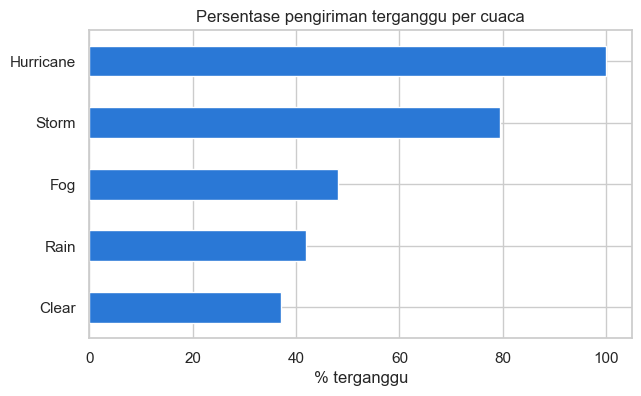

In [12]:
cuaca.plot(kind="barh", color="#2a78d6", figsize=(7, 4))
plt.title("Persentase pengiriman terganggu per cuaca")
plt.xlabel("% terganggu")
plt.ylabel("")
plt.show()

### Uji statistik (H1)
**Alasan:** Grafik menunjukkan Clear paling aman dan Hurricane paling berisiko. Chi-square menguji apakah perbedaan itu nyata secara keseluruhan; uji pasangan (dengan koreksi Bonferroni) menunjukkan *kondisi mana saja* yang berbeda satu sama lain, misalnya apakah Rain benar-benar berbeda dari Clear.

In [13]:
chi_cuaca = uji_chi2(df, "Weather_Condition")
lapor_chi2("H1 - Cuaca vs gangguan", chi_cuaca)

pw_cuaca = uji_pairwise(df, "Weather_Condition")
pw_cuaca

H1 - Cuaca vs gangguan
  Chi-square = 1243.4, df = 4, p = <0.001, Cramér's V = 0.499 (efek sedang)
  → Persentase gangguan BERBEDA SIGNIFIKAN antar kelompok.


,Pembanding,Selisih (poin %),CI 95%,p-value,p (Bonferroni),Signifikan?
0,Hurricane vs Storm,20.5,[18.0; 23.0],<0.001,<0.001,Ya
1,Hurricane vs Fog,51.9,[48.9; 55.0],<0.001,<0.001,Ya
2,Hurricane vs Rain,58.0,[54.9; 61.1],<0.001,<0.001,Ya
3,Hurricane vs Clear,63.0,[60.0; 66.0],<0.001,<0.001,Ya
4,Storm vs Fog,31.5,[27.5; 35.4],<0.001,<0.001,Ya
5,Storm vs Rain,37.6,[33.6; 41.6],<0.001,<0.001,Ya
6,Storm vs Clear,42.6,[38.7; 46.5],<0.001,<0.001,Ya
7,Fog vs Rain,6.1,[1.8; 10.4],0.006,0.059,Tidak
8,Fog vs Clear,11.1,[6.8; 15.4],<0.001,<0.001,Ya
9,Rain vs Clear,5.0,[0.7; 9.3],0.024,0.237,Tidak


## 7. Eksplorasi 2 (H2): Moda Transportasi vs Lead Time
**Alasan:** Pemilihan moda adalah keputusan yang bisa dikendalikan perusahaan, sehingga hasilnya langsung actionable. Kita pakai **median** karena tidak terpengaruh nilai ekstrem. Lead time dan gangguan dilihat bersamaan agar tidak salah memilih: moda tercepat belum tentu paling andal.

In [14]:
moda = df.groupby("Transport_Mode")["Lead_Time_Days"].median().sort_values()

moda

Transport_Mode
Air      0.930
Road     9.295
Rail    11.540
Sea     21.790
Name: Lead_Time_Days, dtype: float64

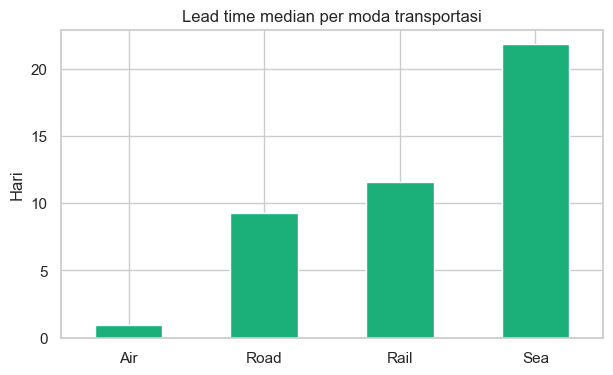

In [15]:
moda.plot(kind="bar", color="#1baf7a", figsize=(7, 4))
plt.title("Lead time median per moda transportasi")
plt.ylabel("Hari")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

### Uji statistik (H2)
**Alasan:** Lead time bersifat miring ke kanan (rata-rata 19,4 hari vs median 8,2 hari), sehingga dipakai uji non-parametrik: **Kruskal-Wallis** (semua moda sekaligus) dan **Mann-Whitney** (per pasangan moda). Kita juga menguji apakah moda berpengaruh pada *peluang gangguan*, karena moda tercepat belum tentu paling andal.

In [16]:
kw_moda = uji_kruskal(df, "Transport_Mode", "Lead_Time_Days")
print(f"H2 - Lead time antar moda: Kruskal-Wallis H = {kw_moda['H']:.1f}, p = {fmt_p(kw_moda['p'])}")
print("  → " + ("Lead time BERBEDA SIGNIFIKAN antar moda." if kw_moda["p"] < ALPHA else "Lead time tidak berbeda signifikan antar moda."))
print()

chi_moda = uji_chi2(df, "Transport_Mode")
lapor_chi2("H2 (tambahan) - Moda vs peluang gangguan", chi_moda)

uji_pairwise_numerik(df, "Transport_Mode", "Lead_Time_Days")

H2 - Lead time antar moda: Kruskal-Wallis H = 2642.7, p = <0.001
  → Lead time BERBEDA SIGNIFIKAN antar moda.

H2 (tambahan) - Moda vs peluang gangguan
  Chi-square = 0.2, df = 3, p = 0.980, Cramér's V = 0.006 (efek sangat kecil)
  → TIDAK berbeda signifikan; selisih yang terlihat bisa jadi hanya kebetulan sampel.


,Pembanding,Selisih median (hari),p-value,p (Bonferroni),Signifikan?
0,Sea vs Rail,10.25,<0.001,<0.001,Ya
1,Sea vs Road,12.50,<0.001,<0.001,Ya
2,Sea vs Air,20.86,<0.001,<0.001,Ya
3,Rail vs Road,2.24,<0.001,<0.001,Ya
4,Rail vs Air,10.61,<0.001,<0.001,Ya
5,Road vs Air,8.36,<0.001,<0.001,Ya


## 8. Eksplorasi 3 (H3): Risiko Geopolitik vs Gangguan
**Alasan:** Skor geopolitik berupa angka kontinu (0–10), sulit dibaca langsung. Dikelompokkan menjadi Rendah / Sedang / Tinggi agar mudah dibandingkan dan dikomunikasikan ke manajemen. Batas 4 dan 7,5 adalah asumsi awal; kita tampilkan jumlah data per kelompok untuk memastikan tidak ada kelompok yang terlalu kecil, dan batas bisa disesuaikan jika perlu.

In [17]:
# Kelompokkan skor 0-10 menjadi 3 kelompok: Rendah, Sedang, Tinggi
df["Kelompok_Geo"] = pd.cut(
    df["Geopolitical_Risk_Score"],
    bins=[0, 4, 7.5, 10],
    labels=["Rendah", "Sedang", "Tinggi"],
    include_lowest=True,
)
geo = df.groupby("Kelompok_Geo", observed=True).agg(
    persen_terganggu=("Disruption_Occurred", lambda s: s.mean() * 100),
    jumlah=("Disruption_Occurred", "size"),
)
print(geo.round(1))

              persen_terganggu  jumlah
Kelompok_Geo                          
Rendah                    49.8    1955
Sedang                    64.7    1816
Tinggi                    74.5    1229


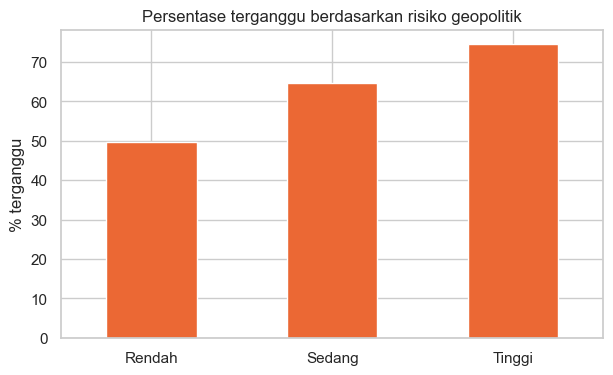

Insight: risiko Tinggi 74.5% vs Rendah 49.8% terganggu.


In [18]:
geo["persen_terganggu"].plot(kind="bar", color="#eb6834", figsize=(7, 4))
plt.title("Persentase terganggu berdasarkan risiko geopolitik")
plt.ylabel("% terganggu")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

print(f"Insight: risiko Tinggi {geo.loc['Tinggi','persen_terganggu']:.1f}% vs Rendah {geo.loc['Rendah','persen_terganggu']:.1f}% terganggu.")

### Uji statistik (H3)
**Alasan:** Memastikan bahwa selisih antara kelompok risiko Rendah, Sedang, dan Tinggi (49,8% → 64,7% → 74,5%) bukan kebetulan. Skor geopolitik juga diuji dalam bentuk aslinya (kontinu, tanpa pengelompokan) dengan korelasi point-biserial, supaya hasilnya tidak bergantung pada pilihan batas 4 dan 7,5.

In [19]:
chi_geo = uji_chi2(df, "Kelompok_Geo")
lapor_chi2("H3 - Risiko geopolitik vs gangguan", chi_geo)

r_geo, p_geo = stats.pointbiserialr(df[TARGET], df["Geopolitical_Risk_Score"])
print(f"  Skor kontinu (tanpa pengelompokan): r = {r_geo:.3f}, p = {fmt_p(p_geo)}")
print()
pw_geo = uji_pairwise(df, "Kelompok_Geo")
pw_geo

H3 - Risiko geopolitik vs gangguan
  Chi-square = 207.9, df = 2, p = <0.001, Cramér's V = 0.204 (efek kecil)
  → Persentase gangguan BERBEDA SIGNIFIKAN antar kelompok.
  Skor kontinu (tanpa pengelompokan): r = 0.225, p = <0.001



,Pembanding,Selisih (poin %),CI 95%,p-value,p (Bonferroni),Signifikan?
0,Tinggi vs Sedang,9.7,[6.5; 13.0],<0.001,<0.001,Ya
1,Tinggi vs Rendah,24.7,[21.4; 28.0],<0.001,<0.001,Ya
2,Sedang vs Rendah,14.9,[11.8; 18.1],<0.001,<0.001,Ya


## 9. Eksplorasi 4 (H4): Reliabilitas Carrier vs Gangguan
**Alasan:** Carrier adalah faktor lain yang bisa dikendalikan (dipilih atau diganti). Jika carrier berskor rendah jauh lebih sering terganggu, maka seleksi carrier menjadi tuas mitigasi yang efektif. Kelompok dibuat dengan *tercile* (3 kelompok berjumlah sama) agar perbandingannya seimbang.

                  persen_terganggu  lead_time_rata2  jumlah
Kelompok_Carrier                                           
Rendah                        65.2             19.4    1673
Sedang                        62.8             19.5    1666
Tinggi                        55.7             19.2    1661


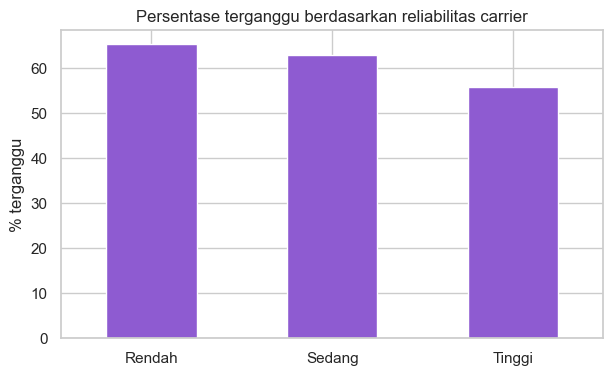

Insight: carrier reliabilitas Rendah 65.2% vs Tinggi 55.7% terganggu.


In [20]:
df["Kelompok_Carrier"] = pd.qcut(df["Carrier_Reliability_Score"], q=3, labels=["Rendah", "Sedang", "Tinggi"])
carrier = df.groupby("Kelompok_Carrier", observed=True).agg(
    persen_terganggu=("Disruption_Occurred", lambda s: s.mean() * 100),
    lead_time_rata2=("Lead_Time_Days", "mean"),
    jumlah=("Disruption_Occurred", "size"),
)
print(carrier.round(1))

carrier["persen_terganggu"].plot(kind="bar", color="#8e5bd1", figsize=(7, 4))
plt.title("Persentase terganggu berdasarkan reliabilitas carrier")
plt.ylabel("% terganggu")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

print(f"Insight: carrier reliabilitas Rendah {carrier.loc['Rendah','persen_terganggu']:.1f}% vs Tinggi {carrier.loc['Tinggi','persen_terganggu']:.1f}% terganggu.")

### Uji statistik (H4): reliabilitas carrier
**Alasan:** Selisih carrier Rendah (65,2%) vs Tinggi (55,7%) tampak kecil dibanding cuaca, sehingga perlu dipastikan apakah *benar-benar berbeda signifikan*. Diuji dengan: (1) chi-square tiga kelompok, (2) uji z dua proporsi Rendah vs Tinggi lengkap dengan **selisih dan CI 95%**, (3) *relative risk* agar mudah dikomunikasikan ("carrier rendah 1,x kali lebih sering terganggu"), dan (4) skor reliabilitas dalam bentuk kontinu. Lead time juga diuji karena rata-ratanya hampir sama antar kelompok.

In [21]:
chi_carrier = uji_chi2(df, "Kelompok_Carrier")
lapor_chi2("H4 - Reliabilitas carrier vs gangguan", chi_carrier)

# Perbandingan langsung Rendah vs Tinggi
rendah = df.loc[df["Kelompok_Carrier"] == "Rendah", TARGET]
tinggi = df.loc[df["Kelompok_Carrier"] == "Tinggi", TARGET]
z_carrier = uji_proporsi(rendah, tinggi)
rr_carrier = rendah.mean() / tinggi.mean()
print(f"\nRendah vs Tinggi: selisih = {z_carrier['selisih']:.1f} poin %, CI 95% [{z_carrier['lo']:.1f}; {z_carrier['hi']:.1f}], p = {fmt_p(z_carrier['p'])}")
print(f"Relative risk: carrier Rendah {rr_carrier:.2f}x lebih sering terganggu dibanding carrier Tinggi")

# Skor reliabilitas kontinu
r_car, p_car = stats.pointbiserialr(df[TARGET], df["Carrier_Reliability_Score"])
print(f"Skor kontinu: r = {r_car:.3f}, p = {fmt_p(p_car)} (negatif = makin andal, makin jarang terganggu)")

# Apakah reliabilitas memengaruhi lead time?
kw_car = uji_kruskal(df, "Kelompok_Carrier", "Lead_Time_Days")
print(f"Lead time antar kelompok carrier: Kruskal-Wallis p = {fmt_p(kw_car['p'])} → "
      + ("berbeda signifikan" if kw_car["p"] < ALPHA else "tidak berbeda signifikan"))
print()
pw_carrier = uji_pairwise(df, "Kelompok_Carrier")
pw_carrier

H4 - Reliabilitas carrier vs gangguan
  Chi-square = 33.7, df = 2, p = <0.001, Cramér's V = 0.082 (efek sangat kecil)
  → Persentase gangguan BERBEDA SIGNIFIKAN antar kelompok.

Rendah vs Tinggi: selisih = 9.4 poin %, CI 95% [6.1; 12.7], p = <0.001
Relative risk: carrier Rendah 1.17x lebih sering terganggu dibanding carrier Tinggi
Skor kontinu: r = -0.079, p = <0.001 (negatif = makin andal, makin jarang terganggu)
Lead time antar kelompok carrier: Kruskal-Wallis p = 0.752 → tidak berbeda signifikan



,Pembanding,Selisih (poin %),CI 95%,p-value,p (Bonferroni),Signifikan?
0,Rendah vs Sedang,2.3,[-0.9; 5.6],0.165,0.495,Tidak
1,Rendah vs Tinggi,9.4,[6.1; 12.7],<0.001,<0.001,Ya
2,Sedang vs Tinggi,7.1,[3.8; 10.4],<0.001,<0.001,Ya


## 10. Eksplorasi 5 (H5): Jarak vs Gangguan dan Lead Time
**Alasan:** Semakin jauh jarak, semakin banyak titik yang bisa bermasalah (pelabuhan, bea cukai, transit). Kita ingin tahu apakah jarak menjelaskan gangguan atau hanya lead time. Hasilnya membantu membedakan "lama karena jauh" (wajar) dari "lama karena terganggu" (bisa dicegah).

                persen_terganggu  lead_time_rata2  jumlah
Kelompok_Jarak                                           
Dekat                       60.4              5.7    1250
Menengah                    61.2             14.6    1250
Jauh                        62.2             24.6    1250
Sangat Jauh                 61.2             32.5    1250


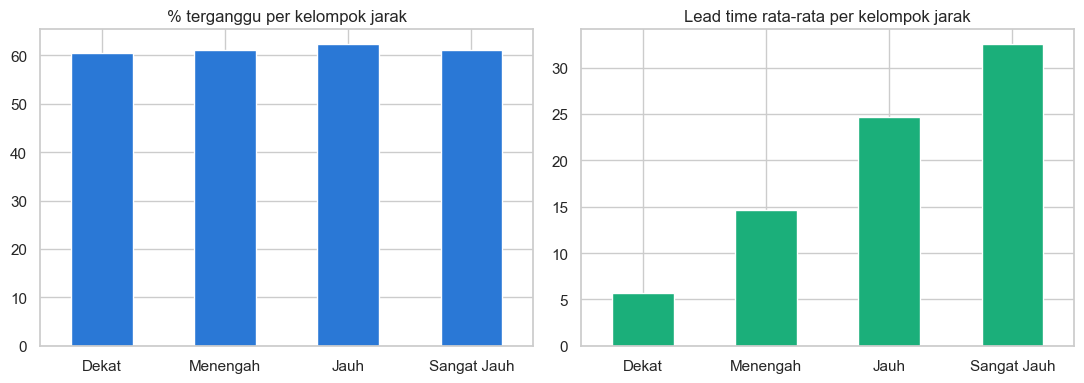

In [22]:
df["Kelompok_Jarak"] = pd.qcut(df["Distance_km"], q=4, labels=["Dekat", "Menengah", "Jauh", "Sangat Jauh"])
jarak = df.groupby("Kelompok_Jarak", observed=True).agg(
    persen_terganggu=("Disruption_Occurred", lambda s: s.mean() * 100),
    lead_time_rata2=("Lead_Time_Days", "mean"),
    jumlah=("Disruption_Occurred", "size"),
)
print(jarak.round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
jarak["persen_terganggu"].plot(kind="bar", ax=ax[0], color="#2a78d6")
ax[0].set_title("% terganggu per kelompok jarak"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)
jarak["lead_time_rata2"].plot(kind="bar", ax=ax[1], color="#1baf7a")
ax[1].set_title("Lead time rata-rata per kelompok jarak"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Uji statistik (H5)
**Alasan:** Tabel di atas memperlihatkan lead time naik tajam seiring jarak, tetapi % gangguan nyaris datar (60-62%). Dua hal itu perlu diuji terpisah: (1) apakah % gangguan berbeda antar kelompok jarak (chi-square), dan (2) seberapa kuat jarak berkaitan dengan lead time (Spearman).

In [23]:
chi_jarak = uji_chi2(df, "Kelompok_Jarak")
lapor_chi2("H5a - Jarak vs gangguan", chi_jarak)
print()

rho_lt, p_lt = stats.spearmanr(df["Distance_km"], df["Lead_Time_Days"])
print(f"H5b - Jarak vs lead time: Spearman rho = {rho_lt:.3f}, p = {fmt_p(p_lt)}")
kw_jarak = uji_kruskal(df, "Kelompok_Jarak", "Lead_Time_Days")
print(f"      Kruskal-Wallis antar kelompok jarak: p = {fmt_p(kw_jarak['p'])}")

H5a - Jarak vs gangguan
  Chi-square = 0.9, df = 3, p = 0.826, Cramér's V = 0.013 (efek sangat kecil)
  → TIDAK berbeda signifikan; selisih yang terlihat bisa jadi hanya kebetulan sampel.

H5b - Jarak vs lead time: Spearman rho = 0.426, p = <0.001
      Kruskal-Wallis antar kelompok jarak: p = <0.001


## 11. Eksplorasi 6 (H6): Tren Waktu
**Alasan:** Gangguan bisa berpola musiman (musim hujan/badai, periode puncak pengiriman, kejadian geopolitik tertentu). Mengetahui bulan rawan memungkinkan perencanaan stok dan kapasitas lebih awal. Jumlah pengiriman per bulan ikut dicek agar lonjakan persentase tidak menyesatkan karena sampel bulan itu sedikit.

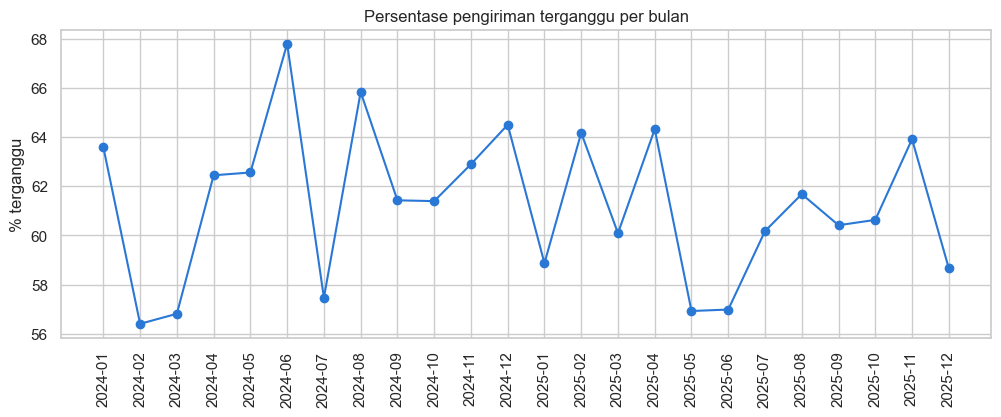

In [24]:
df["Bulan"] = df["Date"].dt.to_period("M").astype(str)

tren = df.groupby("Bulan")["Disruption_Occurred"].mean() * 100

plt.figure(figsize=(12, 4))
plt.plot(tren.index, tren.values, marker="o", color="#2a78d6")
plt.title("Persentase pengiriman terganggu per bulan")
plt.ylabel("% terganggu")
plt.xticks(rotation=90)
plt.show()

### Uji statistik (H6)
**Alasan:** Grafik bulanan selalu tampak naik-turun, padahal sebagian fluktuasi hanyalah *noise* (tiap bulan hanya ± 200 pengiriman). Dua uji dipakai: chi-square antar bulan (apakah ada bulan yang benar-benar berbeda) dan Spearman terhadap urutan bulan (apakah ada tren naik/turun yang konsisten).

In [25]:
chi_tren = uji_chi2(df, "Bulan")
lapor_chi2("H6a - Bulan vs gangguan", chi_tren)

rho_tren, p_tren = stats.spearmanr(np.arange(len(tren)), tren.values)
print(f"\nH6b - Tren linier/monotonik antar bulan: Spearman rho = {rho_tren:.3f}, p = {fmt_p(p_tren)}")
print("  → " + ("Ada tren waktu yang signifikan." if p_tren < ALPHA else "Tidak ada tren waktu yang signifikan."))

H6a - Bulan vs gangguan
  Chi-square = 18.9, df = 23, p = 0.709, Cramér's V = 0.061 (efek sangat kecil)
  → TIDAK berbeda signifikan; selisih yang terlihat bisa jadi hanya kebetulan sampel.

H6b - Tren linier/monotonik antar bulan: Spearman rho = -0.086, p = 0.689
  → Tidak ada tren waktu yang signifikan.


## 12. Korelasi Antar Variabel Numerik
**Alasan:** Ringkasan menyeluruh untuk memeriksa apakah temuan di atas konsisten, dan mencari hubungan yang belum terpikir (misalnya Fuel_Price_Index atau Weight_MT). Ingat: korelasi bukan sebab-akibat, dan `Disruption_Occurred` bersifat biner sehingga korelasinya cenderung kecil walau pengaruhnya nyata. Kolom ini dipakai sebagai pelengkap, bukan pengganti analisis per segmen.

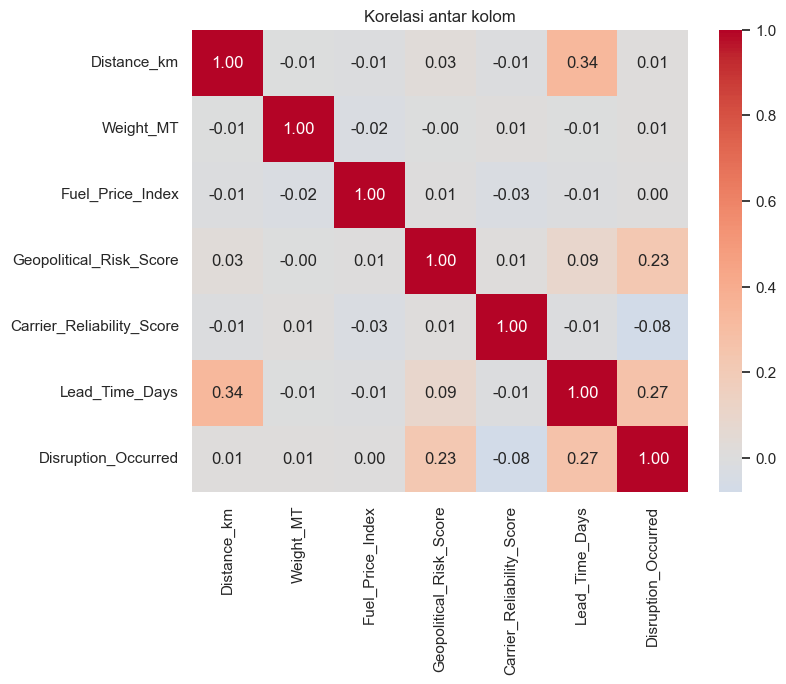

In [26]:
kolom_angka = ["Distance_km", "Weight_MT", "Fuel_Price_Index",
               "Geopolitical_Risk_Score", "Carrier_Reliability_Score",
               "Lead_Time_Days", "Disruption_Occurred"]

korelasi = df[kolom_angka].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar kolom")
plt.show()

## 13. Analisis Multivariat (Dua Faktor atau Lebih Sekaligus)
Analisis di Bagian 6-11 bersifat **univariat**: satu faktor dibandingkan dengan gangguan atau lead time. Padahal faktor-faktor itu bisa saling berkaitan (misalnya carrier yang buruk sering dipakai di jarak tertentu) atau saling memperkuat. Bagian ini menjawab tiga hal:

1. **13.1** Apakah carrier reliabilitas rendah memang dipakai untuk jarak pendek? (dugaan penekanan biaya)
2. **13.2** Apakah efek carrier dan cuaca berjalan sendiri-sendiri atau saling memengaruhi (interaksi)?
3. **13.3-13.5** Faktor mana yang tetap berpengaruh setelah faktor lain dikontrol bersamaan?

### 13.1 Carrier × Jarak: apakah carrier berreliabilitas rendah dipakai untuk jarak pendek?
**Alasan:** Ada dugaan perusahaan menugaskan carrier yang kurang andal untuk pengiriman jarak pendek demi menekan biaya. Jika benar, skor reliabilitas rata-rata akan *lebih rendah* di kelompok jarak Dekat dan naik di kelompok Jauh (korelasi positif). Kita uji dengan Spearman, Kruskal-Wallis, dan chi-square pada tabel silang kelompok carrier × kelompok jarak, lalu melihat apakah efek carrier terhadap gangguan sama di semua jarak.

In [27]:
# (a) Sebaran carrier di tiap kelompok jarak
komposisi = pd.crosstab(df["Kelompok_Jarak"], df["Kelompok_Carrier"], normalize="index") * 100
ringkas_jarak = df.groupby("Kelompok_Jarak", observed=True).agg(
    rata2_reliabilitas=("Carrier_Reliability_Score", "mean"),
    jumlah=("Carrier_Reliability_Score", "size"),
).join(komposisi.add_prefix("% carrier "))
print(ringkas_jarak.round(3))

rho_cj, p_cj = stats.spearmanr(df["Distance_km"], df["Carrier_Reliability_Score"])
kw_cj = uji_kruskal(df, "Kelompok_Jarak", "Carrier_Reliability_Score")
chi_cj = stats.chi2_contingency(pd.crosstab(df["Kelompok_Jarak"], df["Kelompok_Carrier"]))
print(f"\nSpearman jarak vs skor carrier : rho = {rho_cj:.3f}, p = {fmt_p(p_cj)}")
print(f"Kruskal-Wallis skor antar jarak: p = {fmt_p(kw_cj['p'])}")
print(f"Chi-square carrier × jarak     : p = {fmt_p(chi_cj[1])}")

if p_cj >= ALPHA:
    print("\n→ TIDAK ada bukti bahwa carrier reliabilitas rendah lebih banyak dipakai di jarak pendek. "
          "Penugasan carrier tampak tidak dipengaruhi jarak.")
elif rho_cj > 0:
    print("\n→ Mendukung dugaan: makin pendek jarak, makin rendah reliabilitas carrier yang dipakai.")
else:
    print("\n→ Pola kebalikannya: justru jarak jauh yang lebih banyak memakai carrier reliabilitas rendah.")

                rata2_reliabilitas  jumlah  % carrier Rendah  \
Kelompok_Jarak                                                 
Dekat                        0.754    1250             33.68   
Menengah                     0.757    1250             32.96   
Jauh                         0.755    1250             33.20   
Sangat Jauh                  0.751    1250             34.00   

                % carrier Sedang  % carrier Tinggi  
Kelompok_Jarak                                      
Dekat                      33.04             33.28  
Menengah                   33.36             33.68  
Jauh                       34.00             32.80  
Sangat Jauh                32.88             33.12  

Spearman jarak vs skor carrier : rho = -0.012, p = 0.414
Kruskal-Wallis skor antar jarak: p = 0.795
Chi-square carrier × jarak     : p = 0.995

→ TIDAK ada bukti bahwa carrier reliabilitas rendah lebih banyak dipakai di jarak pendek. Penugasan carrier tampak tidak dipengaruhi jarak.


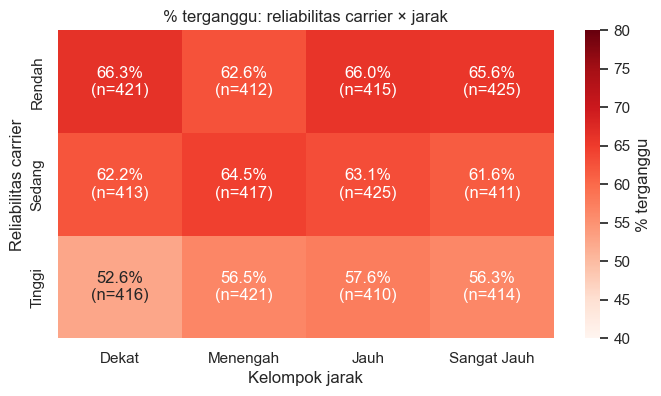

Uji interaksi carrier × jarak: LR = 0.07, p = 0.794 → efek carrier konsisten di semua jarak (tidak ada interaksi).


In [28]:
# (b) % gangguan untuk setiap kombinasi carrier × jarak
pt = df.pivot_table(index="Kelompok_Carrier", columns="Kelompok_Jarak", values=TARGET, aggfunc="mean", observed=True) * 100
n_ = df.pivot_table(index="Kelompok_Carrier", columns="Kelompok_Jarak", values=TARGET, aggfunc="size", observed=True)
label = pt.round(1).astype(str) + "%\n(n=" + n_.astype(str) + ")"

plt.figure(figsize=(8, 4))
sns.heatmap(pt, annot=label.values, fmt="", cmap="Reds", vmin=40, vmax=80, cbar_kws={"label": "% terganggu"})
plt.title("% terganggu: reliabilitas carrier × jarak")
plt.xlabel("Kelompok jarak"); plt.ylabel("Reliabilitas carrier")
plt.show()

# Uji interaksi: apakah efek carrier berbeda di jarak yang berbeda? (likelihood-ratio test)
dfm = df.copy()
dfm["Cuaca_Grup"] = dfm["Weather_Condition"].replace({"Storm": "Storm/Hurricane", "Hurricane": "Storm/Hurricane"})
dfm["Reliabilitas_per_0_1"] = dfm["Carrier_Reliability_Score"] * 10     # efek per kenaikan 0,1 skor
dfm["Jarak_per_1000km"] = dfm["Distance_km"] / 1000
dfm["Geo_Score"] = dfm["Geopolitical_Risk_Score"]

X0 = bangun_X(dfm, ["Reliabilitas_per_0_1", "Jarak_per_1000km"])
X1 = bangun_X(dfm, ["Reliabilitas_per_0_1", "Jarak_per_1000km"], interaksi=[("Reliabilitas_per_0_1", "Jarak_per_1000km")])
_, llf0 = tabel_logit(X0, dfm[TARGET]); _, llf1 = tabel_logit(X1, dfm[TARGET])
lr, p_int_cj = uji_lr(llf0, llf1, X1.shape[1] - X0.shape[1])
print(f"Uji interaksi carrier × jarak: LR = {lr:.2f}, p = {fmt_p(p_int_cj)} → "
      + ("efek carrier BERBEDA menurut jarak." if p_int_cj < ALPHA else "efek carrier konsisten di semua jarak (tidak ada interaksi)."))

### 13.2 Carrier × Cuaca: apakah carrier andal membantu saat cuaca buruk?
**Alasan:** Cuaca tidak bisa dikendalikan, tetapi carrier bisa dipilih. Jika carrier andal terbukti menurunkan gangguan *terutama* saat cuaca buruk (interaksi), maka alokasi carrier terbaik sebaiknya dikhususkan untuk hari berisiko. Jika efeknya sama di semua cuaca, carrier andal berguna setiap saat. Hurricane (100% terganggu) tidak bisa diselamatkan carrier mana pun, sehingga pada uji interaksi Storm dan Hurricane digabung (menghindari *perfect separation* pada regresi).

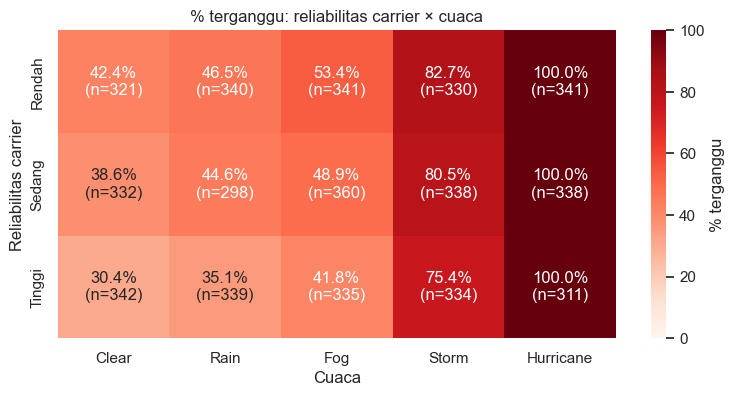

Uji interaksi carrier × cuaca: LR = 0.41, p = 0.938 → efek carrier relatif sama di semua cuaca (tidak ada interaksi); carrier andal membantu setiap saat.


In [29]:
urut_cuaca = list(cuaca.index)   # dari paling aman ke paling berisiko
pt2 = df.pivot_table(index="Kelompok_Carrier", columns="Weather_Condition", values=TARGET, aggfunc="mean", observed=True)[urut_cuaca] * 100
n2 = df.pivot_table(index="Kelompok_Carrier", columns="Weather_Condition", values=TARGET, aggfunc="size", observed=True)[urut_cuaca]
label2 = pt2.round(1).astype(str) + "%\n(n=" + n2.astype(str) + ")"

plt.figure(figsize=(9, 4))
sns.heatmap(pt2, annot=label2.values, fmt="", cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% terganggu"})
plt.title("% terganggu: reliabilitas carrier × cuaca")
plt.xlabel("Cuaca"); plt.ylabel("Reliabilitas carrier")
plt.show()

# Uji interaksi carrier × cuaca (LR test)
X0 = bangun_X(dfm, ["Reliabilitas_per_0_1"], ["Cuaca_Grup"], {"Cuaca_Grup": "Clear"})
X1 = bangun_X(dfm, ["Reliabilitas_per_0_1"], ["Cuaca_Grup"], {"Cuaca_Grup": "Clear"}, interaksi=[("Reliabilitas_per_0_1", "Cuaca_Grup")])
_, llf0 = tabel_logit(X0, dfm[TARGET]); _, llf1 = tabel_logit(X1, dfm[TARGET])
lr, p_int_cw = uji_lr(llf0, llf1, X1.shape[1] - X0.shape[1])
print(f"Uji interaksi carrier × cuaca: LR = {lr:.2f}, p = {fmt_p(p_int_cw)} → "
      + ("efek carrier BERBEDA menurut cuaca." if p_int_cw < ALPHA else
         "efek carrier relatif sama di semua cuaca (tidak ada interaksi); carrier andal membantu setiap saat."))

### 13.3 Moda × Jarak terhadap lead time
**Alasan:** Lead time dipengaruhi moda *dan* jarak sekaligus. Melihat keduanya bersamaan menunjukkan apakah, misalnya, Sea selalu lebih lambat atau hanya pada jarak jauh, dan berapa lead time yang realistis untuk tiap kombinasi (bahan penentuan SLA di Bagian 16).

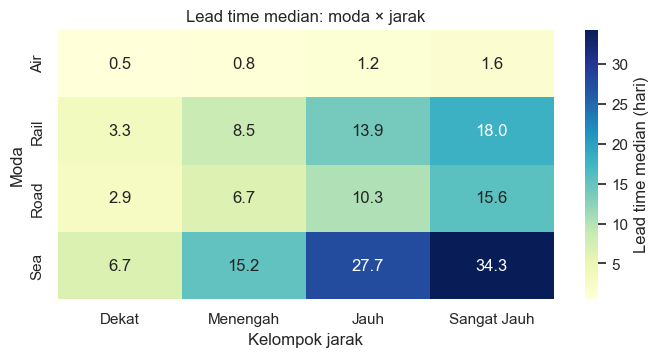

In [30]:
lt_pt = df.pivot_table(index="Transport_Mode", columns="Kelompok_Jarak", values="Lead_Time_Days", aggfunc="median", observed=True)

plt.figure(figsize=(8, 3.5))
sns.heatmap(lt_pt, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Lead time median (hari)"})
plt.title("Lead time median: moda × jarak")
plt.xlabel("Kelompok jarak"); plt.ylabel("Moda")
plt.show()

### 13.4 Regresi logistik: faktor mana yang berpengaruh pada gangguan setelah faktor lain dikontrol?
**Alasan:** Regresi logistik menilai semua faktor **bersamaan**. Hasilnya berupa *odds ratio* (OR): OR > 1 menaikkan peluang gangguan, OR < 1 menurunkannya, dan OR ≈ 1 berarti tidak berpengaruh. Variabel numerik dinyatakan per satuan yang bermakna (+1 poin skor geopolitik, +0,1 skor reliabilitas carrier, +1000 km, +100 MT). Storm dan Hurricane digabung karena Hurricane 100% terganggu (*perfect separation*) sehingga koefisiennya tidak bisa diestimasi. Referensi: cuaca Clear dan moda Road.

                                  Odds Ratio  CI 95% bawah  CI 95% atas  \
Geo_Score                              1.257         1.226        1.289   
Reliabilitas_per_0_1                   0.863         0.823        0.905   
Jarak_per_1000km                       1.000         0.984        1.016   
Fuel_Price_Index                       1.016         0.946        1.091   
Weight_per_100MT                       1.018         0.970        1.067   
Cuaca_Grup_Fog                         1.612         1.337        1.945   
Cuaca_Grup_Rain                        1.208         0.998        1.463   
Cuaca_Grup_Storm/Hurricane            18.573        15.117       22.819   
Transport_Mode_Air                     1.065         0.880        1.289   
Transport_Mode_Rail                    0.996         0.818        1.212   
Transport_Mode_Sea                     1.045         0.862        1.267   
Product_Category_Automotive            0.956         0.770        1.187   
Product_Category_Perishab

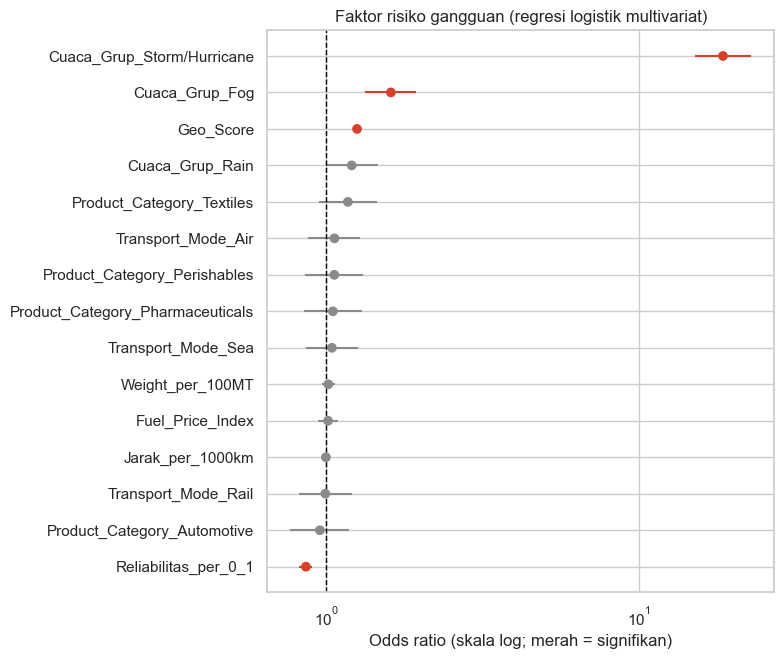


Faktor yang TETAP signifikan setelah faktor lain dikontrol:
  - Cuaca_Grup_Storm/Hurricane: OR = 18.57 (CI 95% 15.12-22.82, p = <0.001)
  - Cuaca_Grup_Fog: OR = 1.61 (CI 95% 1.34-1.94, p = <0.001)
  - Geo_Score: OR = 1.26 (CI 95% 1.23-1.29, p = <0.001)
  - Reliabilitas_per_0_1: OR = 0.86 (CI 95% 0.82-0.91, p = <0.001)
Tidak signifikan: Jarak_per_1000km, Fuel_Price_Index, Weight_per_100MT, Cuaca_Grup_Rain, Transport_Mode_Air, Transport_Mode_Rail, Transport_Mode_Sea, Product_Category_Automotive, Product_Category_Perishables, Product_Category_Pharmaceuticals, Product_Category_Textiles


In [31]:
dfm["Weight_per_100MT"] = dfm["Weight_MT"] / 100

numerik = ["Geo_Score", "Reliabilitas_per_0_1", "Jarak_per_1000km", "Fuel_Price_Index", "Weight_per_100MT"]
kategori = ["Cuaca_Grup", "Transport_Mode", "Product_Category"]
referensi = {"Cuaca_Grup": "Clear", "Transport_Mode": "Road"}

X_log = bangun_X(dfm, numerik, kategori, referensi)
or_tabel, _ = tabel_logit(X_log, dfm[TARGET])
print(or_tabel.round(3))

# Forest plot odds ratio (sumbu log)
plot_df = or_tabel.sort_values("Odds Ratio")
fig, ax = plt.subplots(figsize=(8, 0.35 * len(plot_df) + 1.5))
warna = np.where(plot_df["Signifikan?"] == "Ya", "#d6402a", "#8a8a8a")
ax.hlines(range(len(plot_df)), plot_df["CI 95% bawah"], plot_df["CI 95% atas"], color=warna)
ax.scatter(plot_df["Odds Ratio"], range(len(plot_df)), color=warna, zorder=3)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_xscale("log"); ax.set_yticks(range(len(plot_df))); ax.set_yticklabels(plot_df.index)
ax.set_xlabel("Odds ratio (skala log; merah = signifikan)")
ax.set_title("Faktor risiko gangguan (regresi logistik multivariat)")
plt.tight_layout(); plt.show()

sig = or_tabel[or_tabel["Signifikan?"] == "Ya"].sort_values("Odds Ratio", ascending=False)
print("\nFaktor yang TETAP signifikan setelah faktor lain dikontrol:")
for nama, r in sig.iterrows():
    print(f"  - {nama}: OR = {r['Odds Ratio']:.2f} (CI 95% {r['CI 95% bawah']:.2f}-{r['CI 95% atas']:.2f}, p = {fmt_p(r['p-value'])})")
tidak_sig = [n for n in or_tabel.index if n not in sig.index]
print("Tidak signifikan:", ", ".join(tidak_sig) if tidak_sig else "-")

### 13.5 Regresi untuk lead time: faktor apa yang memperpanjang lead time?
**Alasan:** Lead time miring ke kanan, jadi dimodelkan dalam bentuk log; koefisien dibaca sebagai **perubahan persentase** lead time. Ini memisahkan "lama karena jauh/moda lambat" (wajar) dari "lama karena terganggu" (bisa dicegah), sesuai tujuan Bagian 10.

In [32]:
X_lt = bangun_X(dfm, numerik + [TARGET], ["Cuaca_Grup", "Transport_Mode"], referensi)
ols_tabel, r2_lt = tabel_ols(X_lt, np.log(dfm["Lead_Time_Days"]))
print(f"R² model = {r2_lt:.2f}")
print(ols_tabel.round(3))

print("\nFaktor terbesar yang memperpanjang lead time (signifikan):")
for nama, r in ols_tabel[ols_tabel["Signifikan?"] == "Ya"].sort_values("Efek pada lead time (%)", ascending=False).head(5).iterrows():
    print(f"  - {nama}: {r['Efek pada lead time (%)']:+.0f}% (p = {fmt_p(r['p-value'])})")

R² model = 0.90
                            Efek pada lead time (%)  p-value Signifikan?
Geo_Score                                     3.018    0.000          Ya
Reliabilitas_per_0_1                          0.100    0.831       Tidak
Jarak_per_1000km                             16.306    0.000          Ya
Fuel_Price_Index                             -1.108    0.113       Tidak
Weight_per_100MT                              0.605    0.202       Tidak
Disruption_Occurred                          10.470    0.000          Ya
Cuaca_Grup_Fog                               39.357    0.000          Ya
Cuaca_Grup_Rain                              15.011    0.000          Ya
Cuaca_Grup_Storm/Hurricane                  311.862    0.000          Ya
Transport_Mode_Air                          -88.462    0.000          Ya
Transport_Mode_Rail                          17.679    0.000          Ya
Transport_Mode_Sea                          134.830    0.000          Ya

Faktor terbesar yang memperpanjang

## 14. Ranking Faktor Risiko (menjawab kriteria *Measurable*)
**Alasan:** Agar bisa menentukan prioritas, semua faktor dibandingkan dengan ukuran yang sama: **spread** = selisih % gangguan antara kategori tertinggi dan terendah. Spread besar berarti faktor itu lebih membedakan risiko. Kolom **p-value** dan **Cramér's V** ditambahkan agar jelas faktor mana yang selisihnya *signifikan secara statistik* dan seberapa besar efeknya (bukan sekadar selisih angka).

In [33]:
faktor = {
    "Cuaca": (cuaca, "Weather_Condition"),
    "Moda transportasi": (df.groupby("Transport_Mode")[TARGET].mean() * 100, "Transport_Mode"),
    "Risiko geopolitik": (geo["persen_terganggu"], "Kelompok_Geo"),
    "Reliabilitas carrier": (carrier["persen_terganggu"], "Kelompok_Carrier"),
    "Jarak": (jarak["persen_terganggu"], "Kelompok_Jarak"),
}
baris = {}
for nama, (s, kolom) in faktor.items():
    u = uji_chi2(df, kolom)
    baris[nama] = {
        "Spread (poin %)": float(s.max() - s.min()),
        "Tertinggi": s.idxmax(),
        "Terendah": s.idxmin(),
        "p-value (chi-square)": u["p"],
        "Cramér's V": u["v"],
    }
ranking = pd.DataFrame(baris).T.sort_values("Spread (poin %)", ascending=False)
ranking["Spread (poin %)"] = ranking["Spread (poin %)"].astype(float).round(1)
ranking["Cramér's V"] = ranking["Cramér's V"].astype(float).round(3)
ranking["Signifikan?"] = np.where(ranking["p-value (chi-square)"].astype(float) < ALPHA, "Ya", "Tidak")
ranking["p-value (chi-square)"] = ranking["p-value (chi-square)"].astype(float).map(fmt_p)
ranking

,Spread (poin %),Tertinggi,Terendah,p-value (chi-square),Cramér's V,Signifikan?
Cuaca,63.0,Hurricane,Clear,<0.001,0.499,Ya
Risiko geopolitik,24.7,Tinggi,Rendah,<0.001,0.204,Ya
Reliabilitas carrier,9.4,Rendah,Tinggi,<0.001,0.082,Ya
Jarak,1.8,Jauh,Dekat,0.826,0.013,Tidak
Moda transportasi,0.7,Air,Road,0.980,0.006,Tidak


## 15. Strategi Mitigasi per Kondisi Cuaca
**Alasan:** Cuaca paling aman memang Clear, tetapi pengiriman tidak mungkin hanya dijalankan saat cuaca cerah. Maka pertanyaan yang lebih berguna adalah: *jika cuacanya Rain (atau Fog, Storm, Hurricane), apa yang bisa dilakukan?* Untuk tiap cuaca kita lihat (1) seberapa sering kondisi itu terjadi, (2) tuas yang bisa dikendalikan (carrier dan moda) dan apakah efeknya signifikan di dalam kondisi tersebut, serta (3) *buffer* lead time yang realistis (persentil ke-90). Kolom strategi dibuat otomatis dari hasil uji, bukan ditulis manual.

In [34]:
baris = []
for w in cuaca.index[::-1]:                              # mulai dari cuaca paling berisiko
    sub = df[df["Weather_Condition"] == w]
    car = uji_proporsi(sub.loc[sub["Kelompok_Carrier"] == "Rendah", TARGET],
                       sub.loc[sub["Kelompok_Carrier"] == "Tinggi", TARGET])
    moda_rate = sub.groupby("Transport_Mode")[TARGET].mean() * 100
    chi_m = uji_chi2(sub, "Transport_Mode")
    baris.append({
        "Cuaca": w,
        "% dari total pengiriman": len(sub) / len(df) * 100,
        "n": len(sub),
        "% terganggu": sub[TARGET].mean() * 100,
        "Δ carrier Rendah−Tinggi (poin %)": car["selisih"],
        "p carrier": car["p"],
        "Moda paling andal": moda_rate.idxmin(),
        "Δ moda (maks−min, poin %)": moda_rate.max() - moda_rate.min(),
        "p moda": chi_m["p"],
        "LT median (hari)": sub["Lead_Time_Days"].median(),
        "LT P90 (hari)": sub["Lead_Time_Days"].quantile(0.9),
    })
tuas = pd.DataFrame(baris).set_index("Cuaca")

def strategi(r):
    if r["% terganggu"] >= 95:
        return ("Hampir pasti terganggu dan tidak bisa diselamatkan carrier/moda → hindari atau jadwalkan ulang, "
                "siapkan stok pengaman dan rute alternatif")
    aksi = []
    if r["p carrier"] < ALPHA and r["Δ carrier Rendah−Tinggi (poin %)"] > 0:
        aksi.append(f"alokasikan carrier reliabilitas Tinggi (gangguan turun {r['Δ carrier Rendah−Tinggi (poin %)']:.1f} poin)")
    if r["p moda"] < ALPHA:
        aksi.append(f"utamakan moda {r['Moda paling andal']}")
    aksi.append(f"tambah buffer lead time hingga P90 ≈ {r['LT P90 (hari)']:.0f} hari (median {r['LT median (hari)']:.0f} hari)")
    if r["% terganggu"] >= 60:
        aksi.append("pertimbangkan penundaan pengiriman non-urgent")
    return "; ".join(aksi)

tuas["Strategi"] = tuas.apply(strategi, axis=1)

tampil = tuas.drop(columns="Strategi").copy()
tampil["p carrier"] = tampil["p carrier"].map(fmt_p)
tampil["p moda"] = tampil["p moda"].map(fmt_p)
print(tampil.round(1).to_string())
print()
for w, r in tuas.iterrows():
    print(f"• {w} ({r['% dari total pengiriman']:.0f}% pengiriman, {r['% terganggu']:.0f}% terganggu): {r['Strategi']}")

           % dari total pengiriman     n  % terganggu  Δ carrier Rendah−Tinggi (poin %) p carrier Moda paling andal  Δ moda (maks−min, poin %) p moda  LT median (hari)  LT P90 (hari)
Cuaca                                                                                                                                                                                 
Hurricane                     19.8   990        100.0                               0.0       n/a               Air                        0.0    n/a              40.0          128.6
Storm                         20.0  1002         79.5                               7.3     0.021              Road                        4.7  0.616              14.7           45.5
Fog                           20.7  1036         48.1                              11.6     0.003              Rail                        4.3  0.803               7.0           24.3
Rain                          19.5   977         42.0                              11

**Buffer lead time per cuaca dan moda** (persentil ke-90, dalam hari). Tabel ini bisa langsung dipakai tim perencanaan: saat prakiraan menunjukkan cuaca tertentu, tambahkan buffer sebesar angka pada moda yang dipakai.

In [35]:
buffer = df.pivot_table(index="Weather_Condition", columns="Transport_Mode", values="Lead_Time_Days",
                        aggfunc=lambda s: s.quantile(0.9), observed=True).loc[cuaca.index[::-1]]
n_buf = df.pivot_table(index="Weather_Condition", columns="Transport_Mode", values="Lead_Time_Days",
                       aggfunc="size", observed=True).loc[cuaca.index[::-1]]
print("Lead time P90 (hari):")
print(buffer.round(1))
print("\nJumlah pengiriman (waspadai sel dengan n kecil):")
print(n_buf)

Lead time P90 (hari):
Transport_Mode     Air  Rail  Road    Sea
Weather_Condition                        
Hurricane          7.2  90.2  81.6  198.4
Storm              2.8  37.5  31.1   69.7
Fog                1.7  18.9  15.2   36.5
Rain               1.3  14.1  12.4   28.6
Clear              1.3  11.6   9.5   24.1

Jumlah pengiriman (waspadai sel dengan n kecil):
Transport_Mode     Air  Rail  Road  Sea
Weather_Condition                      
Hurricane          263   234   237  256
Storm              265   246   243  248
Fog                282   243   254  257
Rain               250   230   260  237
Clear              260   232   220  283


## 16. Estimasi Dampak Finansial
**Alasan:** Rekomendasi lebih mudah disetujui manajemen jika dinyatakan dalam dolar. Dataset ini **tidak memiliki kolom biaya**, sehingga estimasi memakai *asumsi parameter* yang bisa diganti dengan angka riil perusahaan (cukup ubah tiga angka di sel berikut, semua hasil dihitung ulang otomatis). Logikanya:

- **SLA lead time** = lead time "normal" untuk kombinasi moda × jarak, yaitu persentil ke-90 dari pengiriman yang *tidak* terganggu. Pengiriman yang melewati SLA dianggap terlambat.
- **Biaya keterlambatan** = hari terlambat × berat (MT) × biaya per MT per hari (stok menumpuk, stockout, denda).
- **Biaya gangguan tetap** = biaya penanganan per pengiriman yang terganggu (rerouting, ekspedisi darurat, klaim).

> Angka dolar di bawah adalah **ilustrasi berbasis asumsi**, bukan kerugian aktual. Yang bisa diandalkan adalah *perbandingan relatif* antar segmen.

In [36]:
# ================== ASUMSI (ganti dengan angka riil perusahaan) ==================
BIAYA_TETAP_GANGGUAN = 5000        # USD per pengiriman terganggu (penanganan, rerouting, klaim)
BIAYA_TELAT_PER_MT_HARI = 20       # USD per MT per hari melewati SLA
PERSENTIL_SLA = 0.90               # SLA = persentil ke-90 lead time pengiriman normal
PREMI_CARRIER_ANDAL = 0            # USD tambahan per pengiriman bila memakai carrier andal (isi jika ada)
# ====================================================================================

normal = df[df[TARGET] == 0]
sla = (normal.groupby(["Transport_Mode", "Kelompok_Jarak"], observed=True)["Lead_Time_Days"]
             .quantile(PERSENTIL_SLA).rename("SLA_hari").reset_index())
sla_moda = normal.groupby("Transport_Mode")["Lead_Time_Days"].quantile(PERSENTIL_SLA)

fin = df.merge(sla, on=["Transport_Mode", "Kelompok_Jarak"], how="left")
fin["SLA_hari"] = fin["SLA_hari"].fillna(fin["Transport_Mode"].map(sla_moda))
fin["Hari_telat"] = (fin["Lead_Time_Days"] - fin["SLA_hari"]).clip(lower=0)
fin["Biaya_telat"] = fin["Hari_telat"] * fin["Weight_MT"] * BIAYA_TELAT_PER_MT_HARI
fin["Biaya_gangguan"] = fin[TARGET] * BIAYA_TETAP_GANGGUAN
fin["Kerugian_USD"] = fin["Biaya_telat"] + fin["Biaya_gangguan"]

total_rugi = fin["Kerugian_USD"].sum()
rugi_per_gangguan = fin.loc[fin[TARGET] == 1, "Kerugian_USD"].mean()
print(f"Total estimasi kerugian        : ${total_rugi:,.0f}")
print(f"  - biaya gangguan tetap       : ${fin['Biaya_gangguan'].sum():,.0f}")
print(f"  - biaya keterlambatan (SLA)  : ${fin['Biaya_telat'].sum():,.0f}")
print(f"Rata-rata per pengiriman       : ${fin['Kerugian_USD'].mean():,.0f}")
print(f"Rata-rata per pengiriman terganggu : ${rugi_per_gangguan:,.0f}  vs tidak terganggu: ${fin.loc[fin[TARGET]==0, 'Kerugian_USD'].mean():,.0f}")

Total estimasi kerugian        : $243,050,244
  - biaya gangguan tetap       : $15,315,000
  - biaya keterlambatan (SLA)  : $227,735,244
Rata-rata per pengiriman       : $48,610
Rata-rata per pengiriman terganggu : $77,722  vs tidak terganggu: $2,575


### Kerugian per segmen dan per tingkat keterlambatan
**Alasan:** Menjawab pertanyaan seperti "jika lead time melewati SLA sekian hari, kerugiannya sekian dolar". Tabel pertama menunjukkan segmen mana yang menyumbang kerugian terbesar; tabel kedua menunjukkan bagaimana kerugian membesar seiring lamanya keterlambatan.

Per cuaca:
                   pengiriman    total_USD  rata2_per_pengiriman_USD  \
Weather_Condition                                                      
Hurricane                 990  200794713.0                  202823.0   
Storm                    1002   35574973.0                   35504.0   
Fog                      1036    2761690.0                    2666.0   
Rain                      977    2067984.0                    2117.0   
Clear                     995    1850884.0                    1860.0   

                   % dari total kerugian  
Weather_Condition                         
Hurricane                           83.0  
Storm                               15.0  
Fog                                  1.0  
Rain                                 1.0  
Clear                                1.0  

Per reliabilitas carrier:
                  pengiriman   total_USD  rata2_per_pengiriman_USD  \
Kelompok_Carrier                                                     
Rendah          

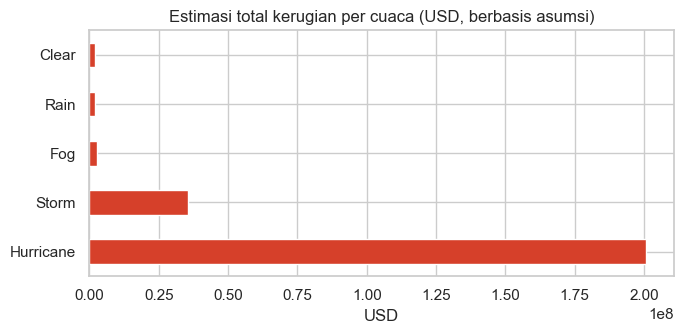

In [37]:
def ringkas_rugi(kolom):
    t = fin.groupby(kolom, observed=True).agg(
        pengiriman=("Kerugian_USD", "size"),
        total_USD=("Kerugian_USD", "sum"),
        rata2_per_pengiriman_USD=("Kerugian_USD", "mean"),
    )
    t["% dari total kerugian"] = t["total_USD"] / total_rugi * 100
    return t.round(0)

rugi_cuaca = ringkas_rugi("Weather_Condition").loc[cuaca.index[::-1]]
print("Per cuaca:");  print(rugi_cuaca)
print("\nPer reliabilitas carrier:");  print(ringkas_rugi("Kelompok_Carrier"))
print("\nPer risiko geopolitik:");  print(ringkas_rugi("Kelompok_Geo"))

# Kerugian menurut lamanya keterlambatan terhadap SLA
fin["Tingkat_telat"] = pd.cut(fin["Hari_telat"], bins=[-0.01, 0, 7, 14, 30, np.inf],
                              labels=["Tepat waktu", "1-7 hari", "8-14 hari", "15-30 hari", ">30 hari"])
rugi_telat = fin.groupby("Tingkat_telat", observed=True).agg(
    pengiriman=("Kerugian_USD", "size"),
    rata2_kerugian_USD=("Kerugian_USD", "mean"),
    total_USD=("Kerugian_USD", "sum"),
).round(0)
print("\nPer tingkat keterlambatan terhadap SLA:"); print(rugi_telat)

rugi_cuaca["total_USD"].plot(kind="barh", color="#d6402a", figsize=(7, 3.5))
plt.title("Estimasi total kerugian per cuaca (USD, berbasis asumsi)")
plt.xlabel("USD"); plt.ylabel("")
plt.tight_layout(); plt.show()

### Skenario mitigasi: berapa potensi penghematannya?
**Alasan:** Mengukur nilai rekomendasi carrier. Skenario: pengiriman yang tadinya memakai carrier reliabilitas Rendah dialihkan ke carrier Tinggi, sehingga % gangguannya turun ke level carrier Tinggi pada segmen yang sama. Penghematan = jumlah gangguan yang terhindar × rata-rata kerugian per gangguan. **Break-even premi** adalah biaya tambahan maksimum per pengiriman untuk carrier andal yang masih membuat skenario ini menguntungkan. Ini estimasi dari asosiasi data, bukan jaminan sebab-akibat.

In [38]:
def skenario(nama, mask):
    rendah = df[mask & (df["Kelompok_Carrier"] == "Rendah")]
    tinggi = df[mask & (df["Kelompok_Carrier"] == "Tinggi")]
    turun = rendah[TARGET].mean() - tinggi[TARGET].mean()            # penurunan peluang gangguan
    terhindar = len(rendah) * turun
    kotor = terhindar * rugi_per_gangguan
    premi_total = len(rendah) * PREMI_CARRIER_ANDAL
    return {
        "Skenario": nama,
        "Pengiriman carrier Rendah dialihkan": len(rendah),
        "Gangguan terhindar": round(terhindar),
        "Penghematan kotor (USD)": round(kotor),
        "Biaya premi (USD)": round(premi_total),
        "Penghematan bersih (USD)": round(kotor - premi_total),
        "Break-even premi (USD/pengiriman)": round(kotor / len(rendah)) if len(rendah) else np.nan,
    }

cuaca_buruk = df["Weather_Condition"].isin(["Rain", "Fog", "Storm"])
skenario_tbl = pd.DataFrame([
    skenario("A. Alihkan semua pengiriman carrier Rendah", pd.Series(True, index=df.index)),
    skenario("B. Alihkan hanya saat Rain/Fog/Storm", cuaca_buruk),
]).set_index("Skenario")
skenario_tbl

,Pengiriman carrier Rendah dialihkan,Gangguan terhindar,Penghematan kotor (USD),Biaya premi (USD),Penghematan bersih (USD),Break-even premi (USD/pengiriman)
Skenario,,,,,,
A. Alihkan semua pengiriman carrier Rendah,1673,157,12226497,0,12226497,7308
B. Alihkan hanya saat Rain/Fog/Storm,1011,100,7809471,0,7809471,7725


## 17. Kesimpulan dan Rekomendasi
**Alasan:** Kesimpulan menghubungkan kembali temuan dengan Objective di Bagian 2. Berbeda dari versi sebelumnya yang hanya mengulang EDA, rekomendasi di sini (a) didukung uji signifikansi dan analisis multivariat, (b) menjawab pertanyaan "bagaimana jika cuaca tidak ideal", dan (c) dinyatakan dalam estimasi dampak finansial. Angka dihasilkan otomatis dari data; kalimat rekomendasi menyesuaikan dengan hasil uji (signifikan atau tidak).

In [39]:
def sig(p):
    return "signifikan" if p < ALPHA else "tidak signifikan"

print("KESIMPULAN")
print("=" * 70)
print(f"1. Baseline: {persen_terganggu:.1f}% dari {total:,} pengiriman terganggu; lead time median {df['Lead_Time_Days'].median():.1f} hari "
      f"(rata-rata {df['Lead_Time_Days'].mean():.1f} hari).")

print("\n2. Faktor yang membedakan peluang gangguan (uji chi-square, urut dari spread terbesar):")
for nama, r in ranking.iterrows():
    print(f"   - {nama}: spread {r['Spread (poin %)']:.1f} poin ({r['Terendah']} → {r['Tertinggi']}), "
          f"p = {r['p-value (chi-square)']} → {'SIGNIFIKAN' if r['Signifikan?']=='Ya' else 'tidak signifikan'}")

print("\n3. Setelah faktor lain dikontrol (regresi logistik), faktor yang tetap signifikan:")
sig_or = or_tabel[or_tabel["Signifikan?"] == "Ya"].sort_values("Odds Ratio", ascending=False)
for nama, r in sig_or.iterrows():
    print(f"   - {nama}: OR = {r['Odds Ratio']:.2f} (p = {fmt_p(r['p-value'])})")

print("\n4. Carrier × jarak: " + (
      "tidak ada bukti carrier reliabilitas rendah dipakai di jarak pendek "
      f"(Spearman rho = {rho_cj:.3f}, p = {fmt_p(p_cj)})." if p_cj >= ALPHA else
      f"ada hubungan jarak dengan reliabilitas carrier (rho = {rho_cj:.3f}, p = {fmt_p(p_cj)})."))

print(f"\n5. Dampak finansial (berdasarkan asumsi): total estimasi kerugian ${total_rugi:,.0f}; "
      f"rata-rata ${rugi_per_gangguan:,.0f} per pengiriman yang terganggu.")

print("\n" + "=" * 70)
print("REKOMENDASI")
print("=" * 70)

# R1: strategi cuaca
print("\nR1. Playbook per kondisi cuaca (tidak bisa hanya mengirim saat Clear):")
for w, r in tuas.iterrows():
    print(f"   • {w} ({r['% dari total pengiriman']:.0f}% pengiriman, {r['% terganggu']:.0f}% terganggu): {r['Strategi']}")
r_rain = tuas.loc["Rain"]
print(f"   Contoh Rain: gangguan {r_rain['% terganggu']:.0f}% vs Clear {cuaca['Clear']:.0f}%; "
      f"carrier andal {'terbukti' if r_rain['p carrier'] < ALPHA else 'belum terbukti'} menurunkan gangguan di cuaca ini "
      f"(selisih {r_rain['Δ carrier Rendah−Tinggi (poin %)']:.1f} poin, p = {fmt_p(r_rain['p carrier'])}).")

# R2: carrier
print(f"\nR2. Seleksi carrier: carrier Rendah {z_carrier['selisih']:.1f} poin lebih sering terganggu daripada Tinggi "
      f"(CI 95% {z_carrier['lo']:.1f} s.d. {z_carrier['hi']:.1f}; p = {fmt_p(z_carrier['p'])}, {sig(z_carrier['p'])}).")
for nama_sk, r in skenario_tbl.iterrows():
    print(f"   - {nama_sk}: potensi penghematan kotor ≈ ${r['Penghematan kotor (USD)']:,.0f}; "
          f"premi carrier andal masih layak selama < ${r['Break-even premi (USD/pengiriman)']:,.0f}/pengiriman.")
print("   " + ("Efek carrier relatif sama di semua cuaca, jadi alokasi carrier andal bermanfaat sepanjang waktu; "
                "prioritaskan lebih dulu pada lane bernilai tinggi." if p_int_cw >= ALPHA else
                "Efek carrier berbeda menurut cuaca; khususkan carrier andal pada kondisi cuaca yang efeknya terbesar (lihat heatmap 13.2)."))

# R3: geopolitik
ge = or_tabel.loc["Geo_Score"]
print(f"\nR3. Risiko geopolitik: tiap kenaikan 1 poin skor menaikkan odds gangguan {((ge['Odds Ratio']-1)*100):.0f}% "
      f"(p = {fmt_p(ge['p-value'])}, {sig(ge['p-value'])}). Pengiriman dengan skor Tinggi ({geo.loc['Tinggi','persen_terganggu']:.1f}% terganggu) "
      "perlu buffer lead time tambahan, rute alternatif, atau pengiriman dipecah.")

# R4: moda dan jarak
print(f"\nR4. Moda dan jarak terhadap gangguan: moda {sig(chi_moda['p'])} (p = {fmt_p(chi_moda['p'])}), "
      f"jarak {sig(chi_jarak['p'])} (p = {fmt_p(chi_jarak['p'])}). Namun keduanya sangat menentukan lead time "
      f"(median Air {moda['Air']:.1f} hari vs Sea {moda['Sea']:.1f} hari). Pilih moda berdasarkan kebutuhan kecepatan dan biaya, "
      "bukan untuk menghindari gangguan; gunakan tabel SLA dan buffer sebagai acuan perencanaan.")

# R5: waktu
print(f"\nR5. Waktu: {'ada tren yang signifikan' if p_tren < ALPHA else 'tidak ditemukan tren atau musiman yang signifikan'} "
      f"(p = {fmt_p(p_tren)}); perencanaan lebih tepat berbasis prakiraan cuaca dan skor geopolitik per pengiriman daripada kalender.")

print("\nKETERBATASAN: analisis bersifat asosiatif (bukan sebab-akibat); estimasi finansial memakai asumsi biaya "
      "dan perlu diganti dengan data biaya riil sebelum dipakai untuk keputusan anggaran.")

KESIMPULAN
1. Baseline: 61.3% dari 5,000 pengiriman terganggu; lead time median 8.2 hari (rata-rata 19.4 hari).

2. Faktor yang membedakan peluang gangguan (uji chi-square, urut dari spread terbesar):
   - Cuaca: spread 63.0 poin (Clear → Hurricane), p = <0.001 → SIGNIFIKAN
   - Risiko geopolitik: spread 24.7 poin (Rendah → Tinggi), p = <0.001 → SIGNIFIKAN
   - Reliabilitas carrier: spread 9.4 poin (Tinggi → Rendah), p = <0.001 → SIGNIFIKAN
   - Jarak: spread 1.8 poin (Dekat → Jauh), p = 0.826 → tidak signifikan
   - Moda transportasi: spread 0.7 poin (Road → Air), p = 0.980 → tidak signifikan

3. Setelah faktor lain dikontrol (regresi logistik), faktor yang tetap signifikan:
   - Cuaca_Grup_Storm/Hurricane: OR = 18.57 (p = <0.001)
   - Cuaca_Grup_Fog: OR = 1.61 (p = <0.001)
   - Geo_Score: OR = 1.26 (p = <0.001)
   - Reliabilitas_per_0_1: OR = 0.86 (p = <0.001)

4. Carrier × jarak: tidak ada bukti carrier reliabilitas rendah dipakai di jarak pendek (Spearman rho = -0.012, p = 0.414).


In [40]:
df.to_csv("/Users/herlinaherlina/Downloads/data_hasil_olahan.csv")
print("File tersimpan: data_hasil_olahan.csv")

File tersimpan: data_hasil_olahan.csv
